# Лабораторная работа №3. Классификация изображений CNN

**Вариант:** 6 (ResNet152)

**Цель работы:** Научиться классифицировать картинки с помощью свёрточных нейросетей.

**Задание:**
1. Загрузить готовую сеть ResNet152 (обученную на базе ImageNet) и распознать на ней одну картинку из интернета.
2. Загрузить два датасета (`horses_or_humans` и `cats_vs_dogs`), проверить баланс классов и разбить данные на обучение и тест (80 на 20).
3. Сделать свою простую нейросеть, обучить её на обоих датасетах и проверить точность.
4. Взять готовую сеть ResNet152, дообучить её на этих же датасетах и сравнить результаты со своей сетью.


In [1]:
%load_ext autoreload
%autoreload 2

### Импорт библиотек и своих модулей

Подключаем нужные библиотеки и загружаем функции из соседних файлов проекта:
* `dataset.py` — загрузка картинок, удаление битых файлов и создание генераторов для обучения.
* `eval.py` — подсчет предсказаний и вывод метрик.
* `inference.py` — распознавание одной картинки и вывод топ-5 ответов.
* `model.py` — код нашей собственной сети и сети на базе ResNet152.
* `utils.py` — очистка памяти видеокарты и оперативной памяти после обучения.
* `visualization.py` — рисование графиков (гистограмма классов, матрица ошибок, PR-кривые).


In [ ]:
from pathlib import Path

import keras
import tensorflow as tf
from keras.src import Functional
from keras.src.applications.resnet import ResNet152
from keras.src.callbacks import ReduceLROnPlateau, EarlyStopping

from dataset import image_dataframe_from_directory, get_data_loaders, clear_dataset
from eval import display_metrics, get_predictions
from inference import predict_and_show
from model import custom_resnet, pretrained_resnet152
from utils import clear_model_training_session
from visualization import plot_class_distribution

### Проверка готовой сети ResNet152 на одной картинке

Скачиваем готовую сеть `ResNet152` с весами `imagenet`. Берем картинку собаки в очках (`dog_with_glasses.jpg`) и передаем её в функцию `predict_and_show` из файла `inference.py`. Функция сжимает картинку до размера 224x224, прогоняет через сеть и выводит 5 самых вероятных пород.


In [ ]:
pretrained_model: Functional = ResNet152(weights="imagenet")

I0000 00:00:1794304980.903847   29653 service.cc:154] XLA service 0x7de4845d81f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794304980.903865   29653 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 13.2.0[595.99.2]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794304981.042106   29653 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794304982.495064   29653 cuda_dnn.cc:442] Loaded cuDNN version 92801


1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step


I0000 00:00:1794304985.265869   29653 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


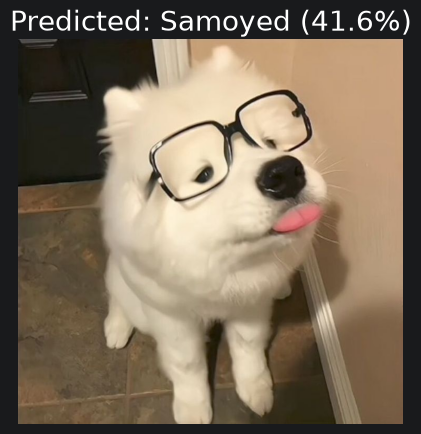

Top-5:
0. Class: Samoyed, Score: 0.42
1. Class: Great_Pyrenees, Score: 0.40
2. Class: Pembroke, Score: 0.07
3. Class: Pekinese, Score: 0.05
4. Class: kuvasz, Score: 0.02


In [4]:
cwd = Path.cwd()
test_img_name: str = "dog_with_glasses.jpg"
img_path: Path = cwd / "assets" / test_img_name
save_path: Path = cwd / "models"

predict_and_show(model=pretrained_model, img_path=img_path)

Удаляем модель и чистим память функцией `clear_model_training_session` из файла `utils.py`.

In [5]:
del pretrained_model
clear_model_training_session()

### Загрузка датасета horses_or_humans и проверка баланса

Собираем список всех картинок в таблицу с помощью функции `image_dataframe_from_directory` из файла `dataset.py`. Затем рисуем диаграмму с количеством картинок через `plot_class_distribution` из файла `visualization.py`. Классы почти равны: 628 лошадей и 655 людей.



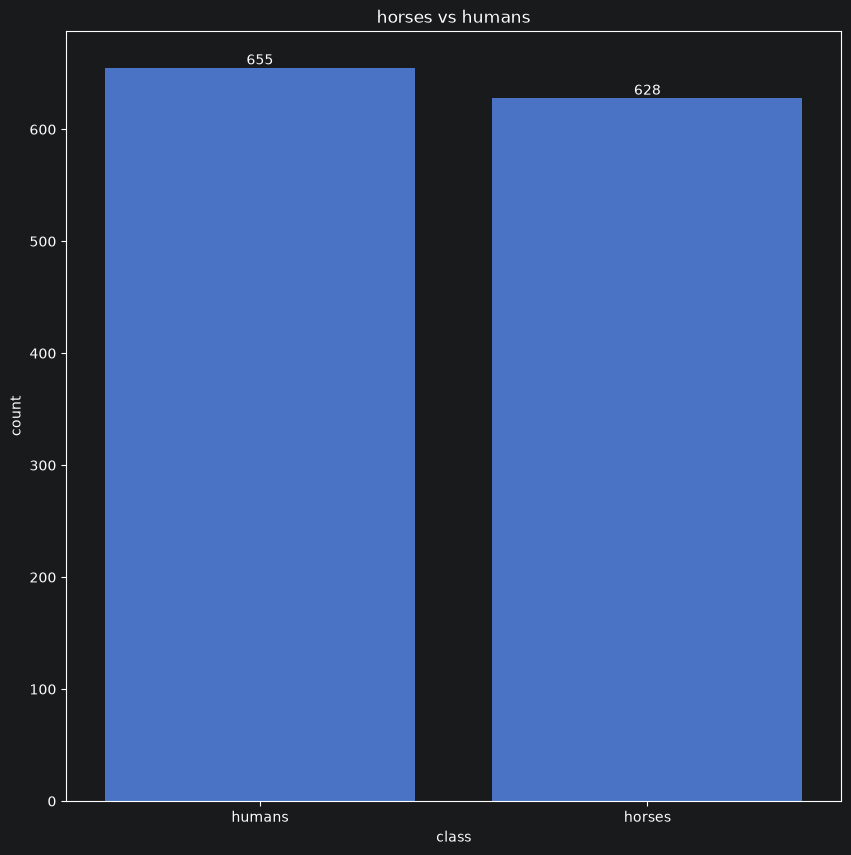

In [6]:
hh_path = cwd / "data" / "horses_or_humans"
hh_df = image_dataframe_from_directory(directory=hh_path)
plot_class_distribution(df=hh_df, class_column="class", title="horses vs humans")

Дальше запускаем `clear_dataset` из файла `dataset.py`, чтобы убрать поврежденные файлы, которые не открываются или содержат не 3 фильтра (RGB). .

In [7]:
clear_dataset(hh_path)

В конце делим картинки на обучающие и проверочные (80/20) с помощью функции `get_data_loaders` из того же файла `dataset.py`.

In [8]:
hh_train, hh_val = get_data_loaders(
    directory_path=hh_path, seed=72, image_size=(224, 224), batch_size=32, validation_split=0.2
)

Found 1283 files belonging to 2 classes.
Using 1027 files for training.
Using 256 files for validation.


### Обучение своей сети на датасете horses_or_humans

Создаем свою небольшую сеть через функцию `custom_resnet` из файла `model.py`. Внутри неё 3 блока со свёртками и нормализацией `LayerNormalization`, а на выходе один нейрон, который выдает вероятность от 0 до 1.

Запускаем обучение максимум на 30 эпох. Чтобы сеть лучше училась и не переобучалась, используем `ReduceLROnPlateau` (уменьшает шаг обучения, если ошибка перестала падать) и `EarlyStopping` (останавливает обучение раньше времени, если результата лучше уже нет). Готовую модель сохраняем в папку `models`.


In [9]:
tf.random.set_seed(72)

hh_callbacks = [
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=3, verbose=1, min_lr=1e-6),
    EarlyStopping(monitor="val_loss", patience=5, verbose=1, restore_best_weights=True),
]

hh_custom_model = custom_resnet(input_shape=(224, 224, 3), model_name="hh_custom_resnet")
hh_custom_model.summary()
hh_custom_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4), loss="binary_crossentropy",
                        metrics=["accuracy"])

history = hh_custom_model.fit(hh_train, validation_data=hh_val, epochs=30, callbacks=hh_callbacks, shuffle=False)

hh_custom_model.save(save_path / "hh_custom_model.keras")

Model: "hh_custom_resnet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │        864 │ rescaling[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 112, 112,  │         64 │ conv2d[0][0]      │
│ (LayerNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ layer_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │     18,432 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_2[0][0]    │
│ (LayerNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 112, 112,  │          0 │ layer_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │      2,048 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │     36,864 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 112, 112,  │          0 │ conv2d_1[0][0],   │
│                     │ 64)               │            │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 112, 112,  │        128 │ add[0][0]         │
│ (LayerNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 112, 112,  │          0 │ layer_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │     73,728 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_5[0][0]    │
│ (LayerNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 56, 56,    │          0 │ layer_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │      8,192 │ activation_2[0][

 Total params: 1,207,201 (4.61 MB)

 Trainable params: 1,207,201 (4.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
 3/33 ━━━━━━━━━━━━━━━━━━━━ 2s 87ms/step - accuracy: 0.4479 - loss: 0.8718 

W0000 00:00:1794299521.387053    4672 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1794299509820331123 in buffer 'PrefetchDataset/_20' sat unconsumed for 11.526 seconds!


33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step - accuracy: 0.5073 - loss: 0.7285

I0000 00:00:1794299529.025700    6700 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'input_add_reduce_fusion_6', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1794299529.096955    6707 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'input_add_reduce_fusion_4', 20 bytes spill stores, 20 bytes spill loads



33/33 ━━━━━━━━━━━━━━━━━━━━ 20s 273ms/step - accuracy: 0.5073 - loss: 0.7285 - val_accuracy: 0.4609 - val_loss: 0.6983 - learning_rate: 1.0000e-04
Epoch 2/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 0.5648 - loss: 0.6758 - val_accuracy: 0.5625 - val_loss: 0.6592 - learning_rate: 1.0000e-04
Epoch 3/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 0.6621 - loss: 0.6044 - val_accuracy: 0.5625 - val_loss: 0.8074 - learning_rate: 1.0000e-04
Epoch 4/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 0.6446 - loss: 0.6099 - val_accuracy: 0.5664 - val_loss: 0.6847 - learning_rate: 1.0000e-04
Epoch 5/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 0.7313 - loss: 0.5398 - val_accuracy: 0.8008 - val_loss: 0.4625 - learning_rate: 1.0000e-04
Epoch 6/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 0.7566 - loss: 0.4939 - val_accuracy: 0.7773 - val_loss: 0.4498 - learning_rate: 1.0000e-04
Epoch 7/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 0.7809 - loss: 0

### Оценка своей сети на датасете horses_or_humans

Получаем ответы обученной сети на тестовых данных через функцию `get_predictions` из файла `eval.py`. Затем передаем их в функцию `display_metrics` (тоже из `eval.py`), которая печатает таблицу с метриками и рисует матрицу ошибок и PR-кривые (сами графики берутся из `visualization.py`).


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 534ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


<Figure size 1000x1000 with 0 Axes>

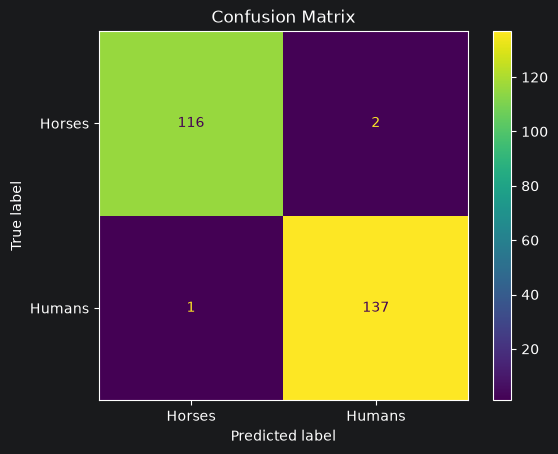

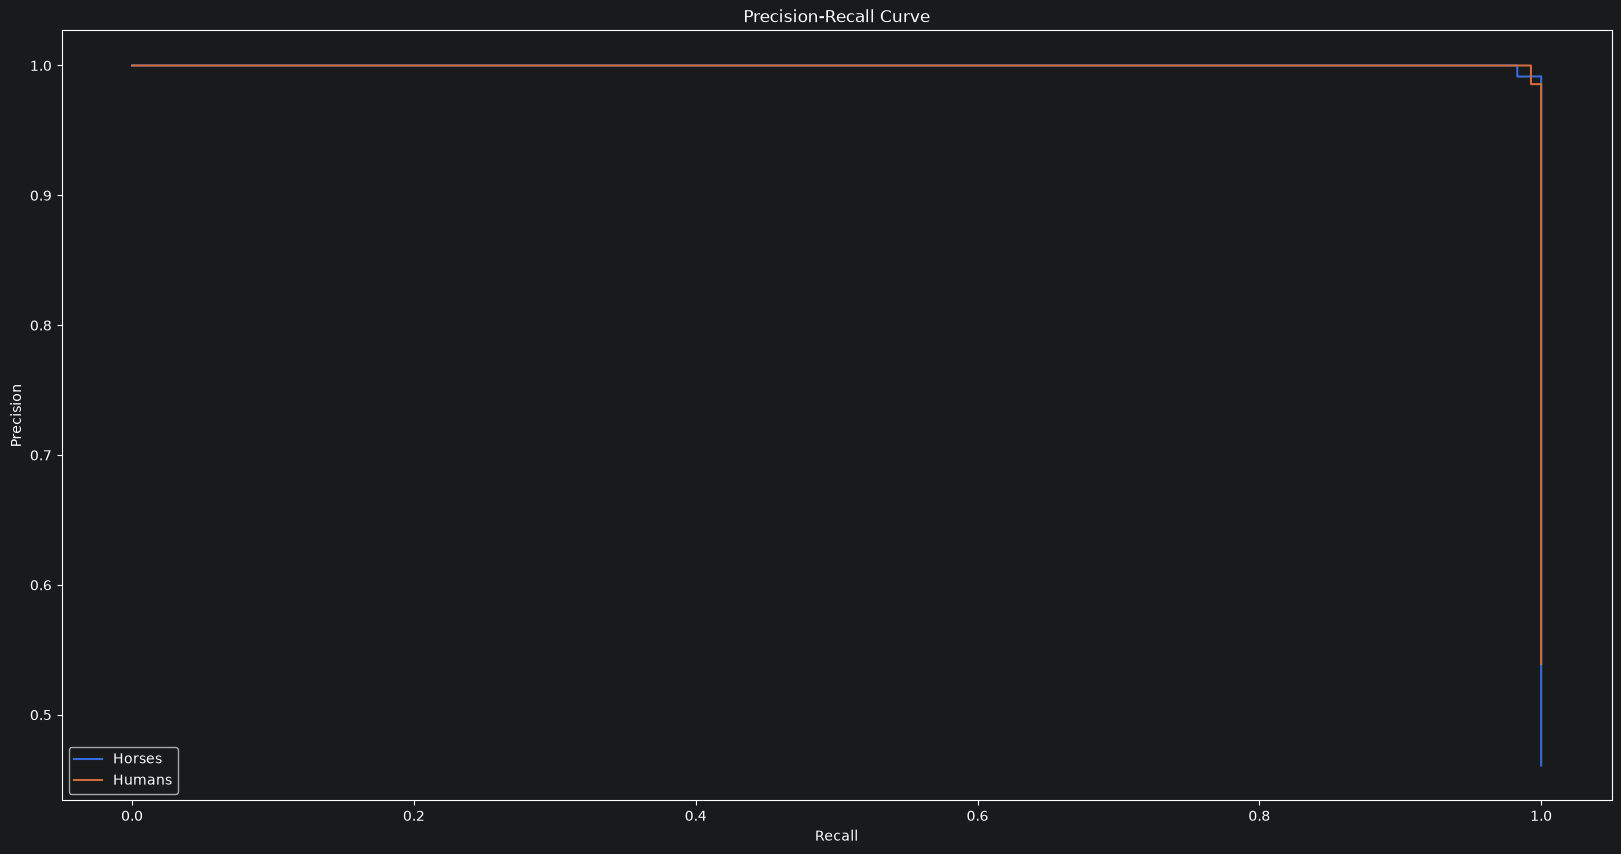

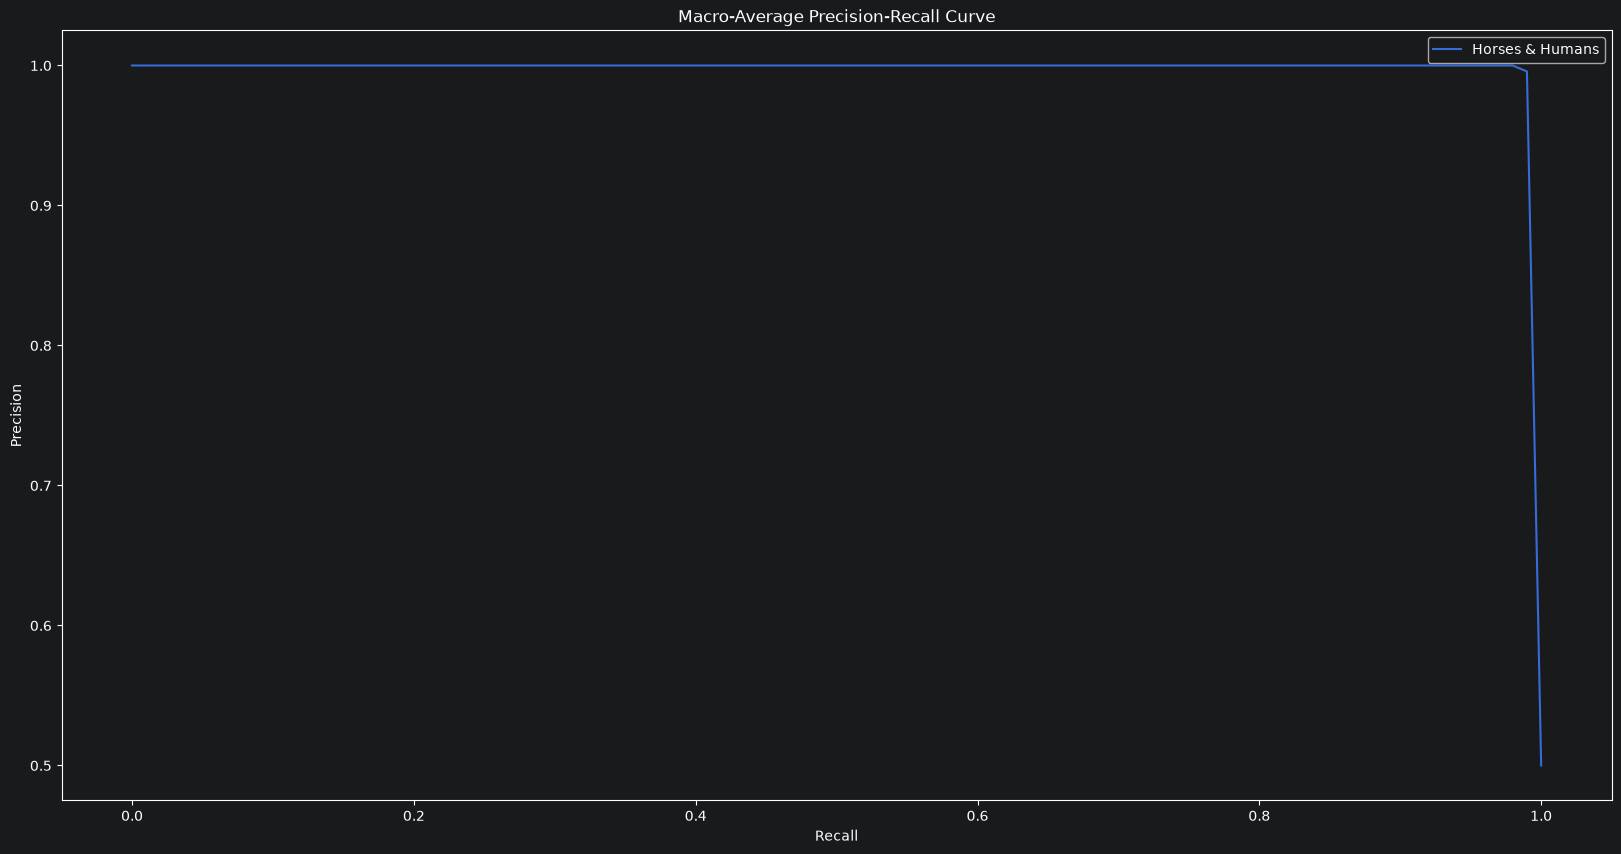

Classification report:
              precision    recall  f1-score   support

      Horses       0.99      0.98      0.99       118
      Humans       0.99      0.99      0.99       138

    accuracy                           0.99       256
   macro avg       0.99      0.99      0.99       256
weighted avg       0.99      0.99      0.99       256



In [10]:
y_true, y_pred, y_prob = get_predictions(hh_custom_model, hh_val)
display_metrics(y_true=y_true, y_pred=y_pred, y_prob=y_prob, target_names=["Horses", "Humans"])

Точность получилась отличная — 99%. После проверки удаляем переменные и очищаем память через `clear_model_training_session` из файла `utils.py`.


### Загрузка датасета cats_vs_dogs и проверка баланса

Делаем всё то же самое для кошек и собак. Собираем таблицу функцией `image_dataframe_from_directory` (`dataset.py`) и рисуем график через `plot_class_distribution` (`visualization.py`). Здесь баланс тоже отличный по 12 500 картинок каждого класса.

Затем функцией `clear_dataset` (`dataset.py`) убираем битые файлы в отдельную папку и создаем генераторы для обучения и теста (80/20) через `get_data_loaders` (`dataset.py`).


In [11]:
del hh_train, hh_val, y_true, y_pred, y_prob, hh_custom_model
clear_model_training_session()

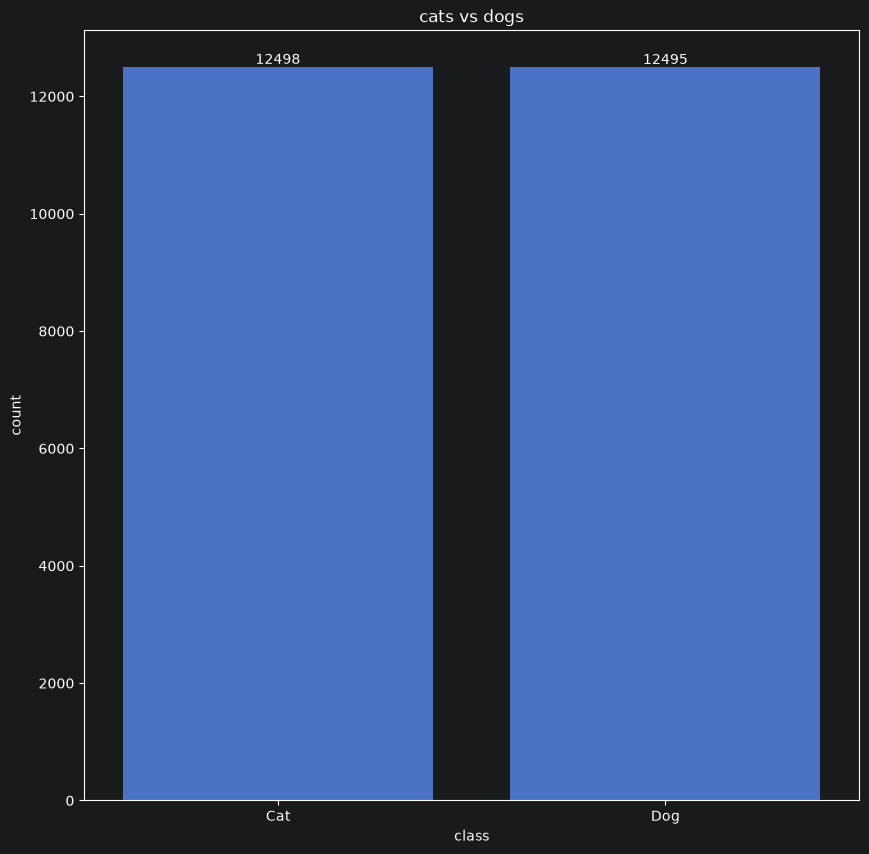

In [7]:
cd_path = cwd / "data" / "cats_vs_dogs"
cd_df = image_dataframe_from_directory(directory=cd_path)
plot_class_distribution(df=cd_df, class_column="class", title="cats vs dogs")

In [13]:
clear_dataset(cd_path)

Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9
Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 99 extraneous bytes before marker 0xd9
Corrupt JPEG data: 214 extraneous bytes before marker 0xd9
Corrupt JPEG data: 128 extraneous bytes before marker 0xd9
Corrupt JPEG data: 396 extraneous bytes before marker 0xd9
Corrupt JPEG data: 252 extraneous bytes before marker 0xd9
Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1403 extraneous bytes before marker 0xd9
Corrupt JPEG data: 228 extraneous bytes before marker 0xd9
Corrupt JPEG data: 162 extraneous bytes before marker 0xd9


In [14]:
cd_train, cd_val = get_data_loaders(directory_path=cd_path, seed=72, image_size=(224, 224), batch_size=32,
                                    validation_split=0.2)

Found 24991 files belonging to 2 classes.
Using 19993 files for training.
Using 4998 files for validation.


### Обучение своей сети на датасете cats_vs_dogs

Создаем новую копию нашей сети через `custom_resnet` из файла `model.py` и обучаем её на кошках и собаках. Настройки такие же: до 30 эпох, уменьшение шага обучения при остановке роста качества и сохранение лучшей модели.


In [15]:
tf.random.set_seed(72)

cd_callbacks = [
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=3, verbose=1, min_lr=1e-6),
    EarlyStopping(monitor="val_loss", patience=5, verbose=1, restore_best_weights=True),
]

cd_custom_model = custom_resnet(input_shape=(224, 224, 3), model_name="cd_custom_resnet")
cd_custom_model.summary()
cd_custom_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4), loss="binary_crossentropy",
                        metrics=["accuracy"])

history = cd_custom_model.fit(cd_train, validation_data=cd_val, epochs=30, callbacks=cd_callbacks, shuffle=False)

cd_custom_model.save(save_path / "cd_custom_model.keras")

Model: "cd_custom_resnet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │        864 │ rescaling[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 112, 112,  │         64 │ conv2d[0][0]      │
│ (LayerNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ layer_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │     18,432 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_2[0][0]    │
│ (LayerNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 112, 112,  │          0 │ layer_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │      2,048 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │     36,864 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 112, 112,  │          0 │ conv2d_1[0][0],   │
│                     │ 64)               │            │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 112, 112,  │        128 │ add[0][0]         │
│ (LayerNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 112, 112,  │          0 │ layer_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │     73,728 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_5[0][0]    │
│ (LayerNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 56, 56,    │          0 │ layer_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │      8,192 │ activation_2[0][

 Total params: 1,207,201 (4.61 MB)

 Trainable params: 1,207,201 (4.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
182/625 ━━━━━━━━━━━━━━━━━━━━ 37s 84ms/step - accuracy: 0.5240 - loss: 0.7011

... (550 outputs left out)

Corrupt JPEG data: 239 extraneous bytes before marker 0xd9


625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.9186 - loss: 0.2212

Corrupt JPEG data: 128 extraneous bytes before marker 0xd9
Corrupt JPEG data: 162 extraneous bytes before marker 0xd9
Corrupt JPEG data: 228 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


625/625 ━━━━━━━━━━━━━━━━━━━━ 58s 93ms/step - accuracy: 0.9186 - loss: 0.2212 - val_accuracy: 0.8549 - val_loss: 0.3321 - learning_rate: 2.0000e-05
Restoring model weights from the end of the best epoch: 29.


### Оценка своей сети на датасете cats_vs_dogs

Проверяем модель на тестовых картинках кошек и собак с помощью функций `get_predictions` и `display_metrics` из файла `eval.py`.



1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 525ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step


Corrupt JPEG data: 128 extraneous bytes before marker 0xd9


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


Corrupt JPEG data: 162 extraneous bytes before marker 0xd9


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━

Corrupt JPEG data: 228 extraneous bytes before marker 0xd9


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━

<Figure size 1000x1000 with 0 Axes>

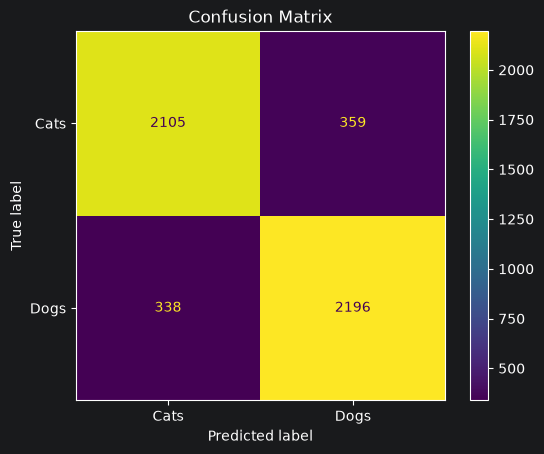

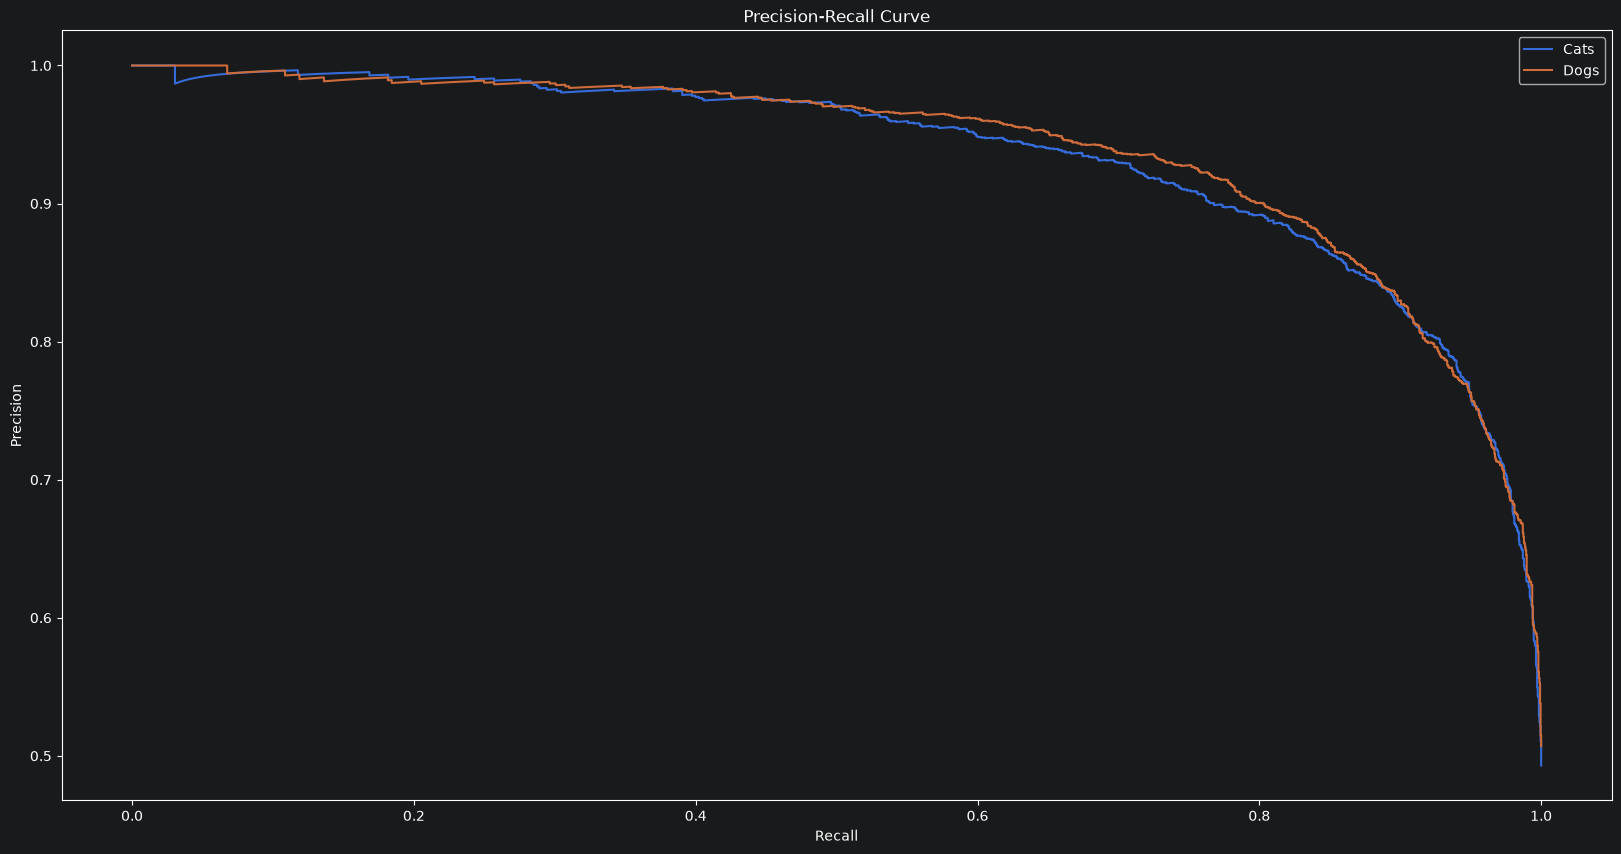

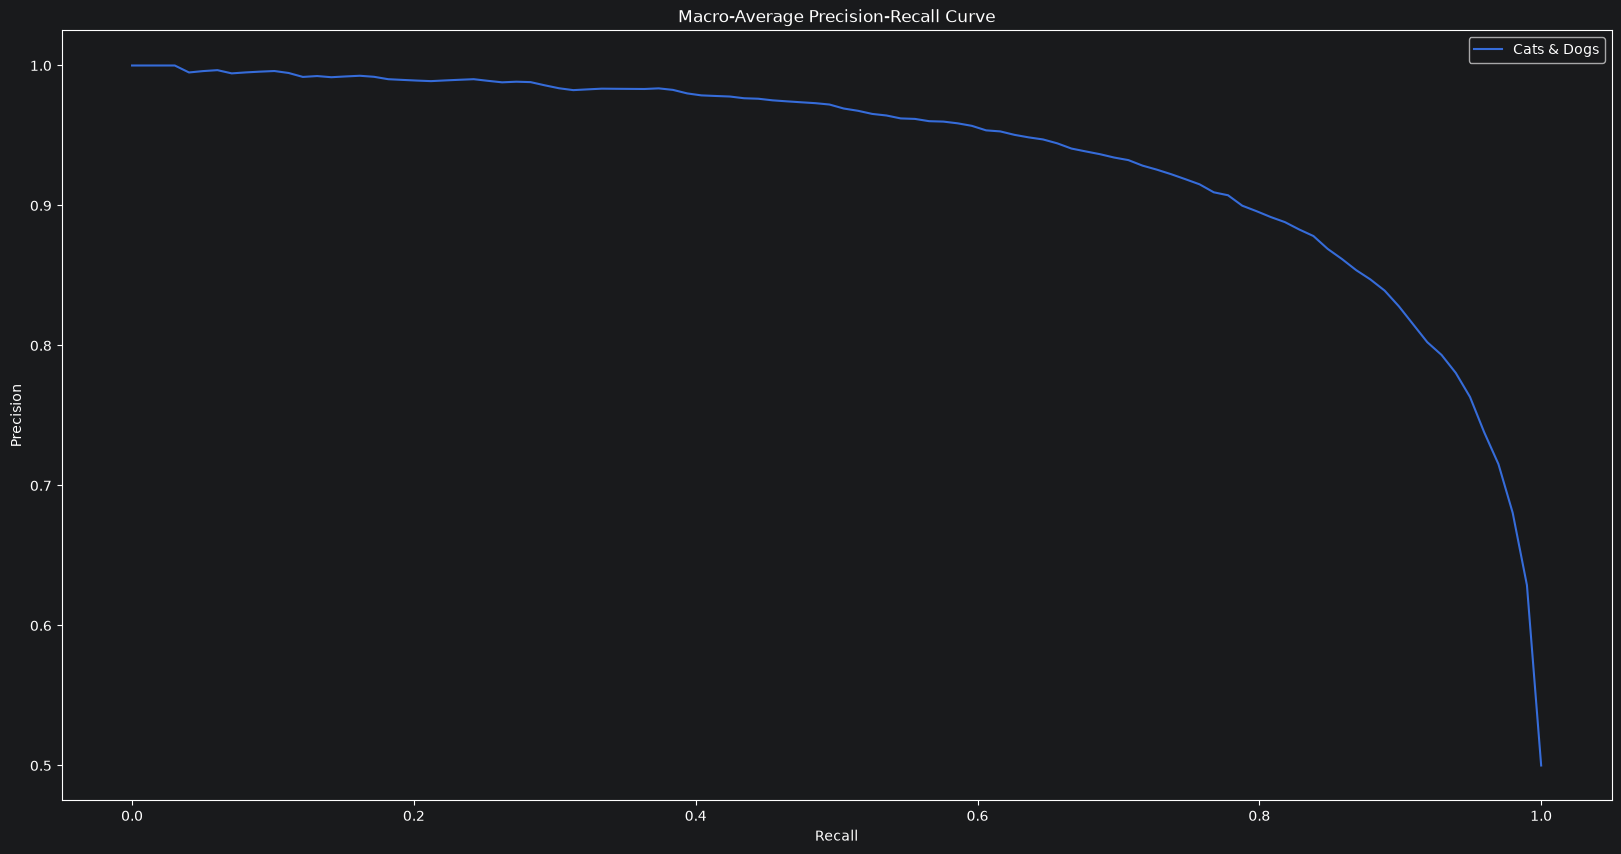

Classification report:
              precision    recall  f1-score   support

        Cats       0.86      0.85      0.86      2464
        Dogs       0.86      0.87      0.86      2534

    accuracy                           0.86      4998
   macro avg       0.86      0.86      0.86      4998
weighted avg       0.86      0.86      0.86      4998



In [16]:
y_true, y_pred, y_prob = get_predictions(cd_custom_model, cd_val)
display_metrics(y_true=y_true, y_pred=y_pred, y_prob=y_prob, target_names=["Cats", "Dogs"])

Этот датасет намного сложнее и разнообразнее первого, поэтому наша маленькая сеть из 3 блоков набрала здесь 86% точности. Ошибается она одинаково часто и на кошках, и на собаках. В конце чистим память через `clear_model_training_session` (`utils.py`).

In [17]:
del cd_train, cd_val, y_true, y_pred, y_prob, cd_custom_model
clear_model_training_session()

### Дообучение ResNet152 на датасете horses_or_humans

Снова загружаем генераторы для лошадей и людей через `get_data_loaders` (`dataset.py`). Создаем модель для дообучения функцией `pretrained_resnet152` из файла `model.py`. Внутри этой функции берется готовая сеть `ResNet152`, её собственные веса замораживаются (не меняются при обучении), а в конец добавляется наш новый выходной слой на 1 нейрон.

Учим только этот последний слой в течение 10 эпох и сохраняем модель.


In [18]:
hh_train, hh_val = get_data_loaders(
    directory_path=hh_path, seed=72, image_size=(224, 224), batch_size=32, validation_split=0.2
)

Found 1283 files belonging to 2 classes.
Using 1027 files for training.
Using 256 files for validation.


In [23]:
tf.random.set_seed(72)

cd_callbacks = [
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=3, verbose=1, min_lr=1e-6),
    EarlyStopping(monitor="val_loss", patience=5, verbose=1, restore_best_weights=True),
]

hh_pretrained_model = pretrained_resnet152(input_shape=(224, 224, 3), model_name="hh_pretrained_resnet")
hh_pretrained_model.summary()
hh_pretrained_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4), loss="binary_crossentropy",
                        metrics=["accuracy"])

history = hh_pretrained_model.fit(hh_train, validation_data=hh_val, epochs=10, callbacks=cd_callbacks, shuffle=False)

hh_pretrained_model.save(save_path / "hh_pretrained_model.keras")

Model: "hh_pretrained_resnet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_6          │ (None, 224, 224)  │          0 │ input_layer_5[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_7          │ (None, 224, 224)  │          0 │ input_layer_5[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_8          │ (None, 224, 224)  │          0 │ input_layer_5[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_2 (Stack)     │ (None, 224, 224,  │          0 │ get_item_6[0][0], │
│                     │ 3)                │            │ get_item_7[0][0], │
│                     │                   │            │ get_item_8[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 224, 224,  │          0 │ stack_2[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet152           │ (None, 7, 7,      │ 58,370,944 │ add_2[0][0]       │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet152[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │      2,049 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 58,372,993 (222.68 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 58,370,944 (222.67 MB)

Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 22s 440ms/step - accuracy: 0.7644 - loss: 0.5166 - val_accuracy: 0.8984 - val_loss: 0.3830 - learning_rate: 1.0000e-04
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 154ms/step - accuracy: 0.9698 - loss: 0.2944 - val_accuracy: 0.9883 - val_loss: 0.2344 - learning_rate: 1.0000e-04
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 154ms/step - accuracy: 0.9942 - loss: 0.1873 - val_accuracy: 1.0000 - val_loss: 0.1575 - learning_rate: 1.0000e-04
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 156ms/step - accuracy: 0.9961 - loss: 0.1313 - val_accuracy: 1.0000 - val_loss: 0.1153 - learning_rate: 1.0000e-04
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 156ms/step - accuracy: 0.9990 - loss: 0.0976 - val_accuracy: 1.0000 - val_loss: 0.0882 - learning_rate: 1.0000e-04
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 157ms/step - accuracy: 0.9990 - loss: 0.0761 - val_accuracy: 1.0000 - val_loss: 0.0702 - learning_rate: 1.0000e-04
Epoch 7/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 157ms/step - accuracy:

### Оценка дообученной ResNet152 на датасете horses_or_humans

Проверяем точность через `get_predictions` и `display_metrics` из файла `eval.py`.


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step


<Figure size 1000x1000 with 0 Axes>

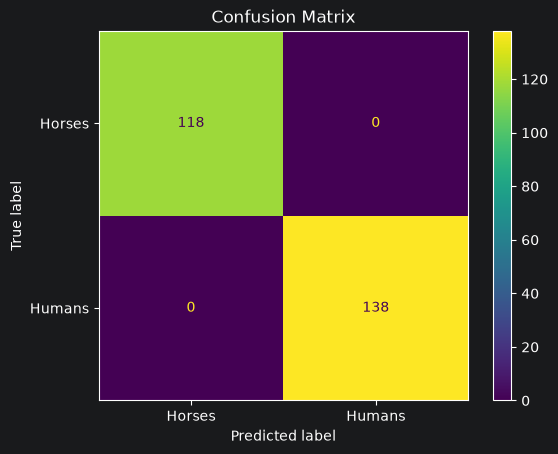

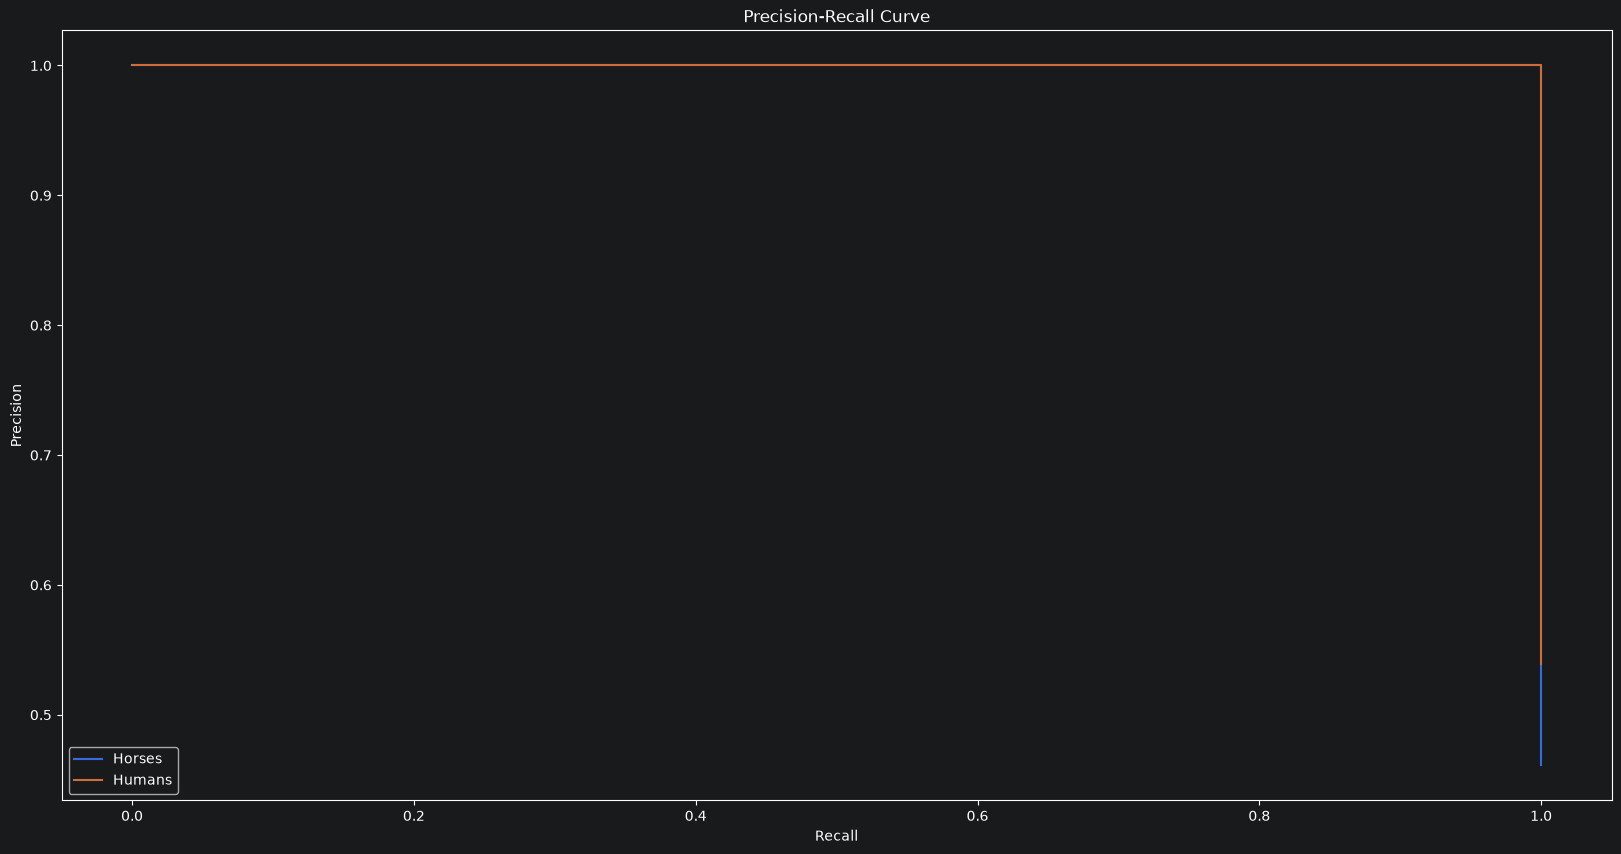

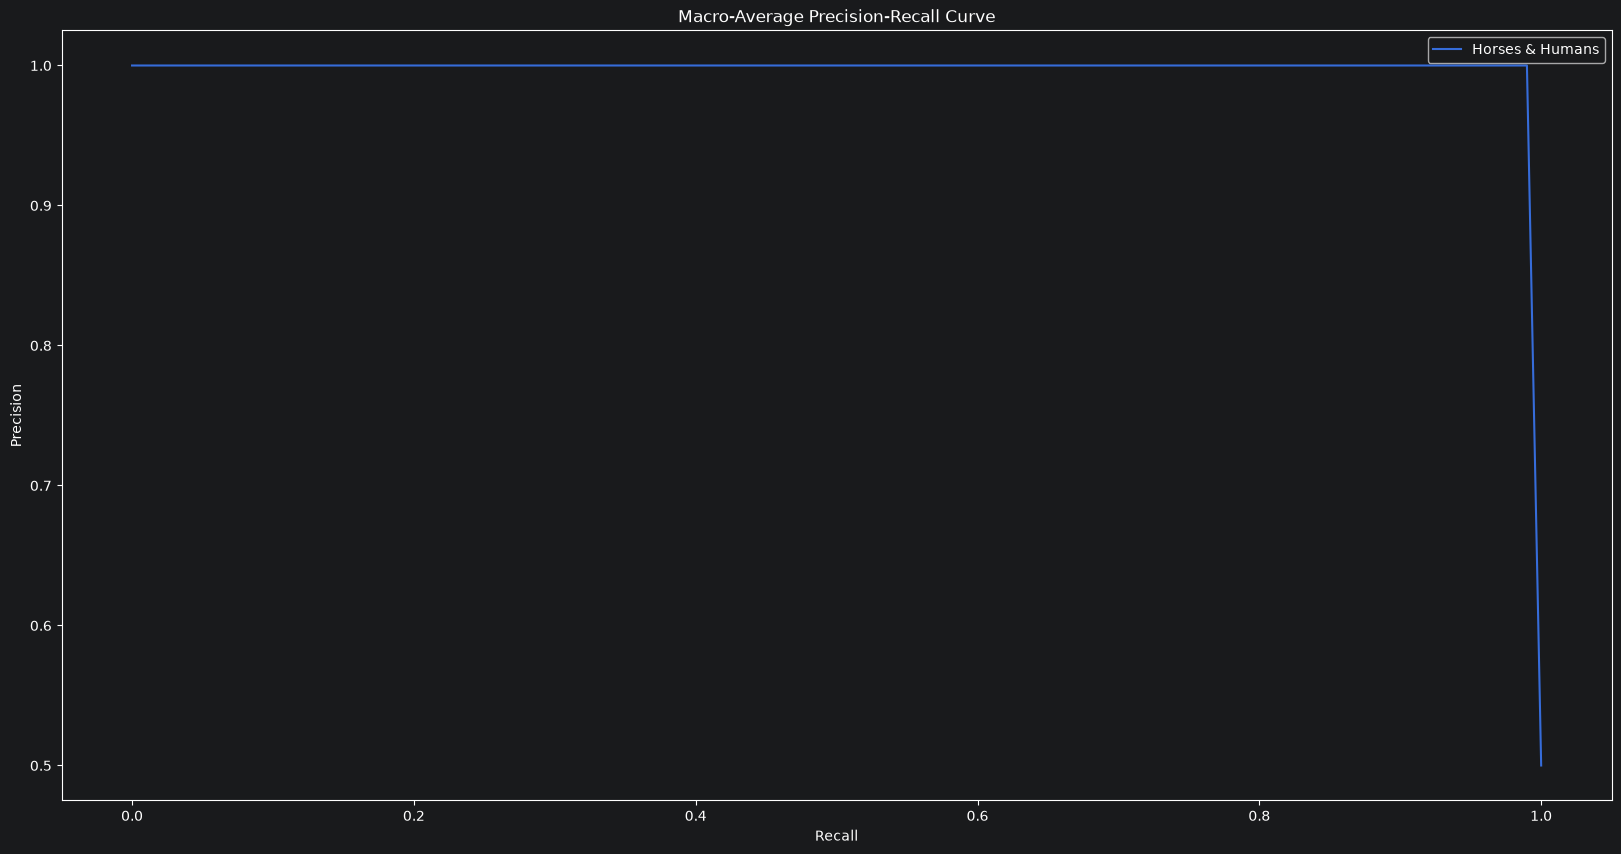

Classification report:
              precision    recall  f1-score   support

      Horses       1.00      1.00      1.00       118
      Humans       1.00      1.00      1.00       138

    accuracy                           1.00       256
   macro avg       1.00      1.00      1.00       256
weighted avg       1.00      1.00      1.00       256



In [24]:
y_true, y_pred, y_prob = get_predictions(hh_pretrained_model, hh_val)
display_metrics(y_true=y_true, y_pred=y_pred, y_prob=y_prob, target_names=["Horses", "Humans"])

 Дообученная сеть `ResNet152` не сделала ни одной ошибки на тестовой выборке и показала 100% точности по всем метрикам. Чистим память функцией `clear_model_training_session` (`utils.py`).

In [25]:
del y_true, y_pred, y_prob, hh_val, hh_train, hh_pretrained_model
clear_model_training_session()

### Дообучение ResNet152 на датасете cats_vs_dogs

Загружаем данные кошек и собак через `get_data_loaders` (`dataset.py`). Создаем вторую модель на базе замороженной `ResNet152` через функцию `pretrained_resnet152` из файла `model.py` и обучаем её 10 эпох.


In [8]:
cd_train, cd_val = get_data_loaders(
    directory_path=cd_path, seed=72, image_size=(224, 224), batch_size=32, validation_split=0.2
)

Found 24991 files belonging to 2 classes.
Using 19993 files for training.
Using 4998 files for validation.


In [9]:
tf.random.set_seed(72)

cd_callbacks = [
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=3, verbose=1, min_lr=1e-6),
    EarlyStopping(monitor="val_loss", patience=5, verbose=1, restore_best_weights=True),
]

cd_pretrained_model = pretrained_resnet152(input_shape=(224, 224, 3), model_name="cd_pretrained_resnet")
cd_pretrained_model.summary()
cd_pretrained_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4), loss="binary_crossentropy",
                            metrics=["accuracy"])

history = cd_pretrained_model.fit(cd_train, validation_data=cd_val, epochs=10, callbacks=cd_callbacks, shuffle=False)

cd_pretrained_model.save(save_path / "cd_pretrained_model.keras")

Model: "cd_pretrained_resnet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet152           │ (None, 7, 7,      │ 58,370,944 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet152[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │      2,049 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 58,372,993 (222.68 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 58,370,944 (222.67 MB)

Epoch 1/10
  2/625 ━━━━━━━━━━━━━━━━━━━━ 1:14 119ms/step - accuracy: 0.4219 - loss: 0.8721 

... (186 outputs left out)

Corrupt JPEG data: 239 extraneous bytes before marker 0xd9


625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.9938 - loss: 0.0207

Corrupt JPEG data: 128 extraneous bytes before marker 0xd9
Corrupt JPEG data: 162 extraneous bytes before marker 0xd9
Corrupt JPEG data: 228 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


625/625 ━━━━━━━━━━━━━━━━━━━━ 98s 156ms/step - accuracy: 0.9938 - loss: 0.0207 - val_accuracy: 0.9938 - val_loss: 0.0216 - learning_rate: 1.0000e-04
Restoring model weights from the end of the best epoch: 10.


### Оценка дообученной ResNet152 на датасете cats_vs_dogs и выводы

Получаем предсказания и строим графики с помощью `get_predictions` и `display_metrics` из файла `eval.py`.



1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step


Corrupt JPEG data: 128 extraneous bytes before marker 0xd9


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

Corrupt JPEG data: 162 extraneous bytes before marker 0xd9


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

Corrupt JPEG data: 228 extraneous bytes before marker 0xd9


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step


Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

<Figure size 1000x1000 with 0 Axes>

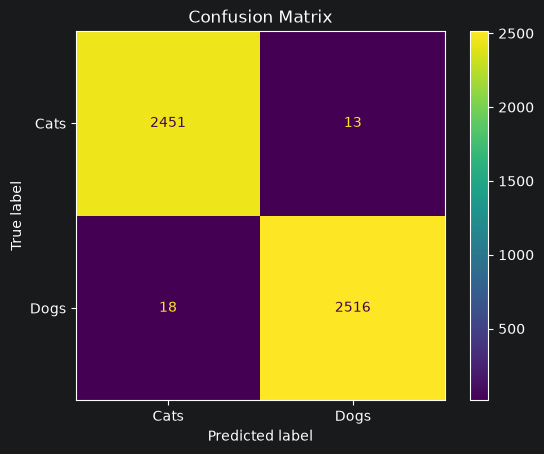

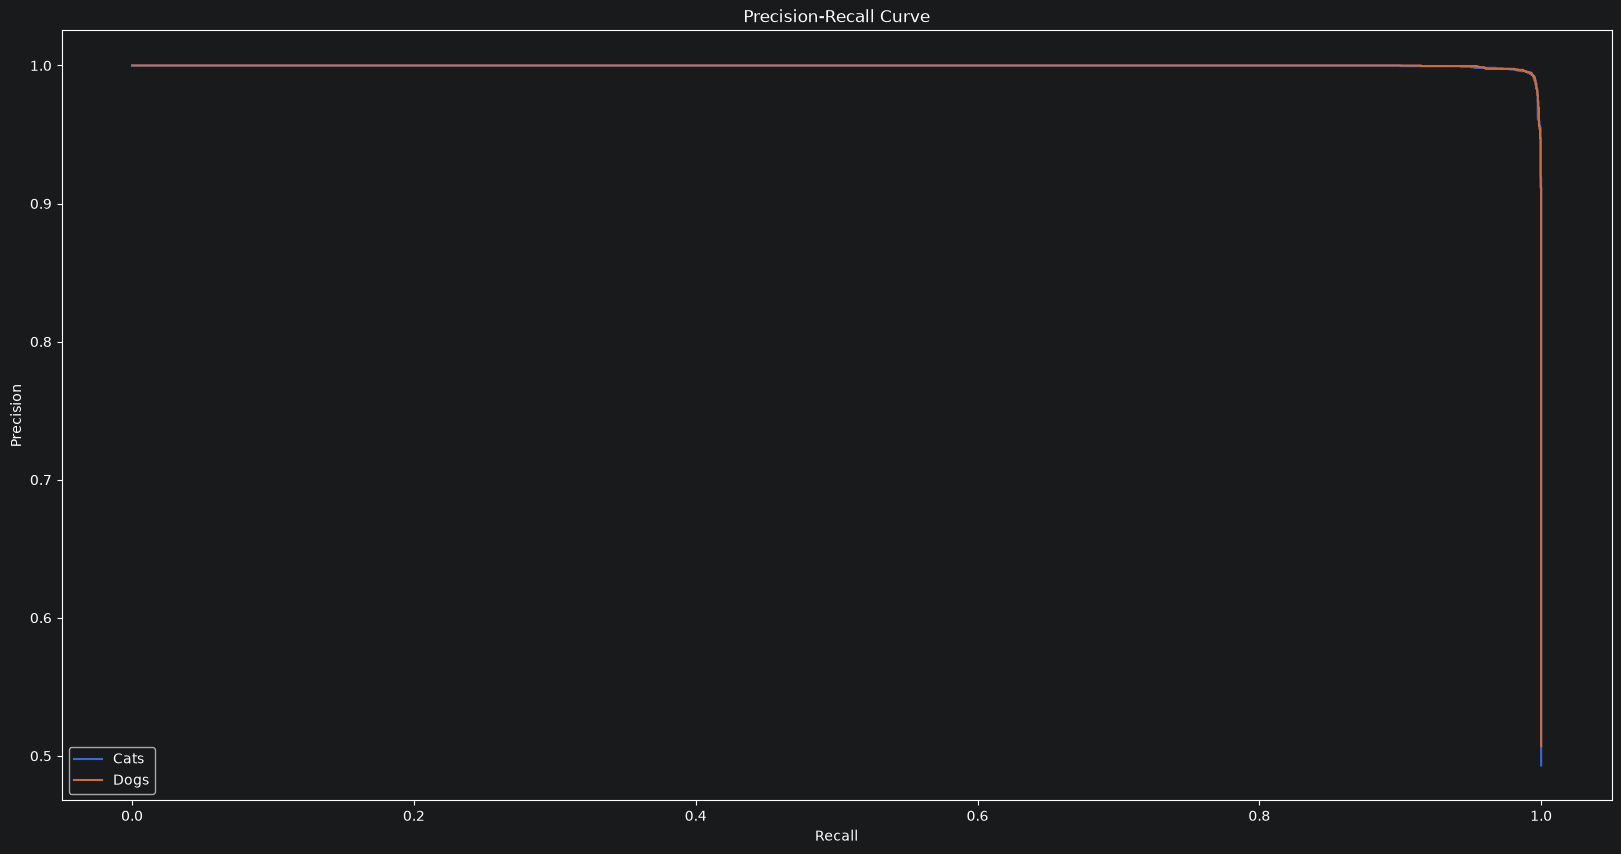

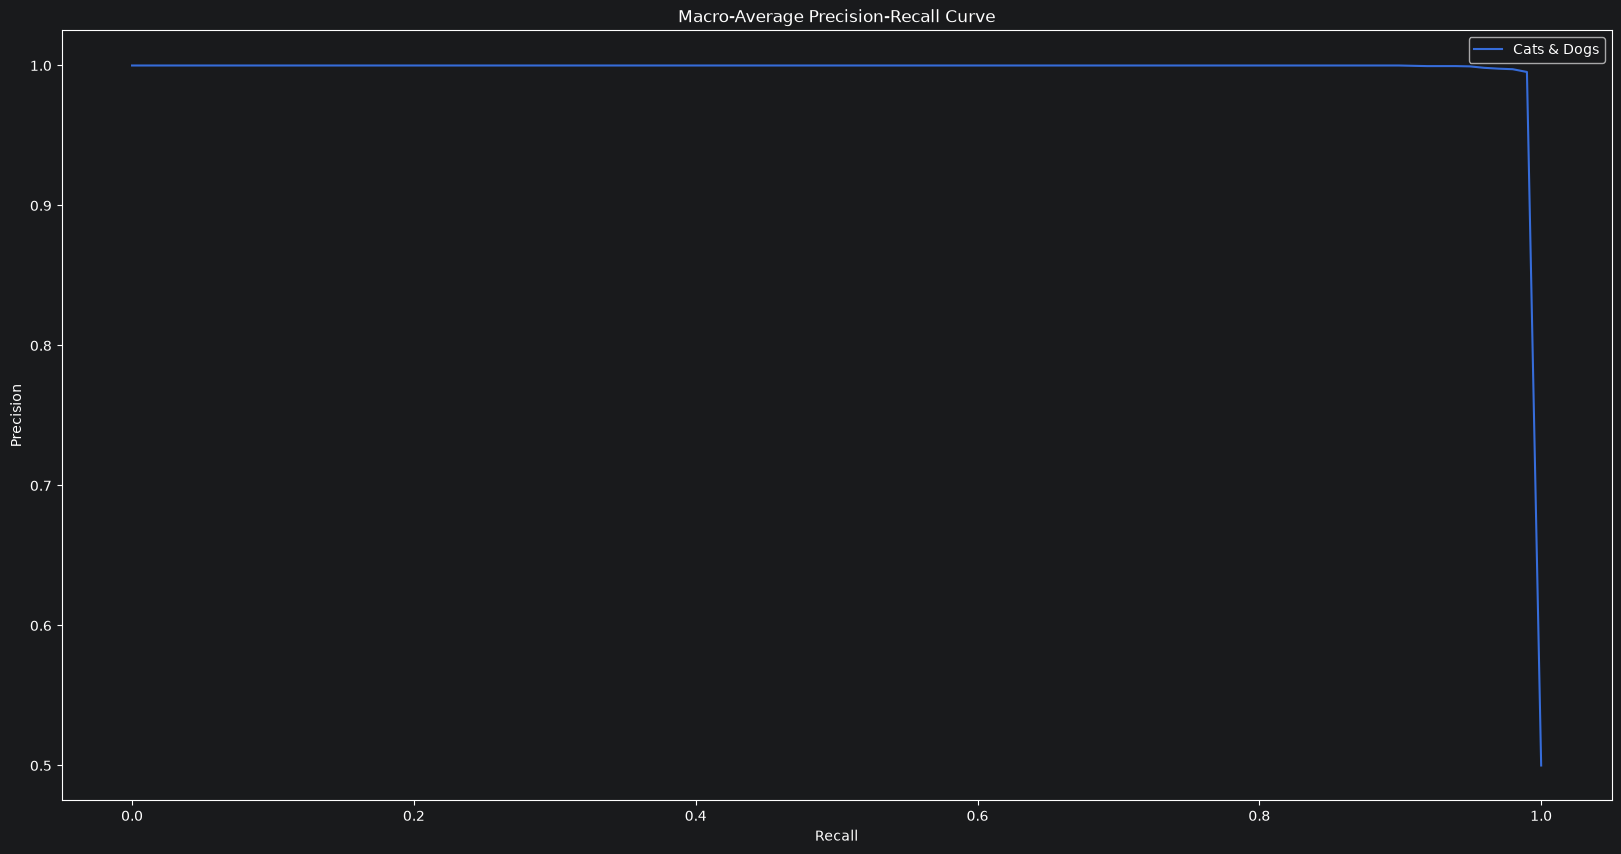

Classification report:
              precision    recall  f1-score   support

        Cats       0.99      0.99      0.99      2464
        Dogs       0.99      0.99      0.99      2534

    accuracy                           0.99      4998
   macro avg       0.99      0.99      0.99      4998
weighted avg       0.99      0.99      0.99      4998



In [10]:
y_true, y_pred, y_prob = get_predictions(cd_pretrained_model, cd_val)
display_metrics(y_true=y_true, y_pred=y_pred, y_prob=y_prob, target_names=["Cats", "Dogs"])

In [11]:
del y_true, y_pred, y_prob, cd_val, cd_train, cd_pretrained_model
clear_model_training_session()

На сложном датасете (`cats_vs_dogs`) дообученная `ResNet152` показала 99% точности и почти идеальные PR-кривые. Это происходит потому, что `ResNet152` гораздо глубже и уже заранее умеет выделять сложные формы и текстуры шерсти благодаря обучению на большой базе ImageNet.

### Вывод по работе


1. **Датасет horses_or_humans:**
   * Оба класса (лошади и люди) распознаются очень легко из-за явных отличий в позах и силуэтах.
   * Наша сеть показала точность **99%**, а дообученная ResNet152 — **100%**. На таком простом наборе данных даже легкая архитектура работает практически без ошибок.

2. **Датасет cats_vs_dogs:**
   * Этот датасет значительно сложнее: ракурсы разнообразнее, а кошки и собаки часто похожи по позе или фону.
   * Наша сеть из 3 блоков набрала **86%** точности. Ей не хватило глубины и емкости, чтобы уловить мелкие различия в текстуре шерсти и строении морды. Ошибки распределились поровну: 359 раз ошиблась на кошках и 338 раз на собаках.
   * Дообученная ResNet152 показала результат **99%** (всего 31 ошибка на 4998 тестовых картинок). PR-кривые идут почти по верхней границе (точность держится на уровне 0.99 практически при любом пороге отсечки).

**Главный итог:** использование готовых весов (Transfer Learning) дает огромный выигрыш на сложных изображениях. ResNet152 уже умеет извлекать мелкие визуальные признаки из ImageNet, поэтому сходится быстрее и ошибается в разы реже, чем небольшая сеть, обученная с нуля.
